In [ ]:
%pip install scikit-learn #Usa %pip install em vez de apenas pip install porque o primeiro instala os pacotes diretamente no ambiente do kernel.

In [22]:
import sklearn
import matplotlib.pyplot as plt
import pandas as pd
import os
import numpy as np

from sklearn.model_selection import train_test_split
from time import perf_counter
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [36]:
PASTA_PRECIP = os.path.join("..", "DATA", "CSV_regioes")   # precipitação
PASTA_ACUDES = os.path.join("..", "DATA", "CSV_acudes")    # volume dos açudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    for nome in sorted(os.listdir(pasta)):
        if nome.lower().endswith(".csv"):
            df = pd.read_csv(os.path.join(pasta, nome), sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(nome)[0]
            lista.append(df)
    if not lista:
        raise FileNotFoundError(f"Nenhum CSV em: {pasta}")
    return lista

df_1 = pd.concat(ler_pasta(PASTA_PRECIP, decimal="."), ignore_index=True)
df_2 = pd.concat(ler_pasta(PASTA_ACUDES, decimal=","), ignore_index=True).rename(columns={"arquivo": "acude"})

display(df_1.head())
display(df_2.head())
print(df_1.dtypes, "\n")
print(df_2.dtypes)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,42.59,reserv_atalho
1,2006-01-02 00:00:00,42.59,reserv_atalho
2,2006-01-03 00:00:00,NaN,reserv_atalho
3,2006-01-04 00:00:00,NaN,reserv_atalho
4,2006-01-05 00:00:00,NaN,reserv_atalho


data             str
lat          float64
lon          float64
precip_mm    float64
municipio        str
estado           str
uf               str
regiao           str
arquivo          str
dtype: object 

DateTime            str
Volume (hm³)    float64
acude               str
dtype: object


Classificação (Alvo Qualitativo/Categórico)

In [24]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Distância em km entre pontos (fórmula de Haversine)."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

coordenadas_acudes = pd.DataFrame({
    "acude":     ["reserv_atalho", "reserv_rosario", "reserv_olhodgua", "reserv_quixabinha"],
    "lat_acude": [-8.75, -6.75, -6.25, -7.25],
    "lon_acude": [-38.25, -39.25, -36.25, -38.75],
})
RAIO_MAXIMO_KM = 50.0

# chave de data em texto, igual nas duas tabelas
df_1["data_str"] = pd.to_datetime(df_1["data"]).dt.strftime("%Y-%m-%d")
df_2["data_str"] = pd.to_datetime(df_2["DateTime"]).dt.strftime("%Y-%m-%d")

# remove linhas repetidas de precipitação (mesma data e mesmo ponto)
antes = len(df_1)
df_1 = df_1.drop_duplicates(subset=["data_str", "lat", "lon"]).reset_index(drop=True)
print(f"Linhas repetidas removidas em df_1: {antes - len(df_1)}")

pontos = df_1[["lat", "lon"]].drop_duplicates().reset_index(drop=True)
mapeamento = []
for _, ac in coordenadas_acudes.iterrows():
    dist = haversine_km(ac["lat_acude"], ac["lon_acude"], pontos["lat"], pontos["lon"])
    i = dist.idxmin()
    if dist.loc[i] <= RAIO_MAXIMO_KM:
        mapeamento.append({
            "acude": ac["acude"],
            "lat_precip_mais_proxima": pontos.loc[i, "lat"],
            "lon_precip_mais_proxima": pontos.loc[i, "lon"],
            "distancia_km": dist.loc[i],
        })
    else:
        print(f"Açude '{ac['acude']}' ignorado: ponto de chuva mais próximo a {dist.loc[i]:.1f} km (limite {RAIO_MAXIMO_KM} km).")

df_map = pd.DataFrame(mapeamento)
if df_map.empty:
    raise ValueError("Nenhum açude atendeu ao critério de distância.")

df_2_geo = df_2.merge(df_map, on="acude", how="inner")
df_unificado = df_2_geo.merge(
    df_1,
    left_on=["data_str", "lat_precip_mais_proxima", "lon_precip_mais_proxima"],
    right_on=["data_str", "lat", "lon"],
    how="inner",
)
print(f"Registros válidos (raio de {RAIO_MAXIMO_KM} km): {len(df_unificado)}")
print(df_unificado["acude"].value_counts())

df_final = df_unificado.rename(columns={
    "DateTime": "Data",
    "Volume (hm³)": "volume",
    "precip_mm": "precipitação",
    "classe_acude": "classe_volume_acude",
    "status_alerta": "bin_status_alerta",
})
cols = ["Data", "acude", "municipio", "estado", "volume", "pct",
        "precipitação", "classe_volume_acude", "bin_status_alerta"]
df_final = df_final[[c for c in cols if c in df_final.columns]].copy()

print(df_final.dtypes)
print(df_final.isna().sum())
display(df_final.head())

Linhas repetidas removidas em df_1: 198
Açude 'reserv_atalho' ignorado: ponto de chuva mais próximo a 111.2 km (limite 50.0 km).
Açude 'reserv_olhodgua' ignorado: ponto de chuva mais próximo a 110.5 km (limite 50.0 km).
Registros válidos (raio de 50.0 km): 15154
acude
reserv_quixabinha    7577
reserv_rosario       7577
Name: count, dtype: int64
Data                str
acude               str
municipio           str
estado              str
volume          float64
precipitação    float64
dtype: object
Data               0
acude              0
municipio          0
estado             0
volume          1417
precipitação       2
dtype: int64


,Data,acude,municipio,estado,volume,precipitação
0,2006-01-01 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,1.460885
1,2006-01-02 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.58,44.768280
2,2006-01-03 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,18.526501
3,2006-01-04 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,0.000000
4,2006-01-05 00:00:00,reserv_quixabinha,Mauriti,Ceará,7.57,0.000000


In [27]:
# 1. Ordenar por açude e data
df_unificado["Data"] = pd.to_datetime(df_unificado["DateTime"])
df_unificado = df_unificado.sort_values(["acude", "Data"]).reset_index(drop=True)

# 2. Renomear colunas para o padrão final
mapa_renomeacao = {
    "Volume (hm³)": "Volume Atual",
    "Volume Atual (v)": "Volume Atual",
    "precip_mm": "Precipitação_Recente",
    "Precipitação Recente": "Precipitação_Recente",
}
df_final = df_unificado.rename(columns=mapa_renomeacao)

# 3. Calcular percentual 'pct' usando o máximo histórico de cada açude
cap_estimada = df_final.groupby("acude")["Volume Atual"].transform("max")
df_final["pct"] = (df_final["Volume Atual"] / cap_estimada) * 100

# 4. Criar o alvo 'classe_volume_acude'
bins = [-1, 10, 30, 50, 70, 101]
labels = ["muito_critico", "critico", "alerta", "confortavel", "muito_confortavel"]
df_final["classe_volume_acude"] = pd.cut(df_final["pct"], bins=bins, labels=labels).astype(str)

# 5. Criar features defasadas (Lag features) POR AÇUDE para evitar vazamento de dados
df_final["Volume Anterior (v-1)"] = df_final.groupby("acude")["Volume Atual"].shift(1)
df_final["Pct Anterior (p-1)"] = df_final.groupby("acude")["pct"].shift(1)
# Opcional: acumulado de chuva dos últimos 7 dias (faz muito sentido hidrologicamente)
df_final["Precip_Acum_7d"] = df_final.groupby("acude")["Precipitação_Recente"].transform(
    lambda x: x.rolling(7, min_periods=1).sum()
)

# 6. Selecionar colunas (mantendo 'acude' para codificação e removendo NaNs do shift)
colunas_selecionadas = [
    "acude",
    "Volume Anterior (v-1)",
    "Pct Anterior (p-1)",
    "Precipitação_Recente",
    "Precip_Acum_7d",
    "Data",
    "classe_volume_acude"
]

df_reduzido = df_final[colunas_selecionadas].dropna().reset_index(drop=True)
display(df_reduzido.head())

,acude,Volume Anterior (v-1),Pct Anterior (p-1),Precipitação_Recente,Precip_Acum_7d,Data,classe_volume_acude
0,reserv_quixabinha,7.58,41.084011,44.768280,46.229165,2006-01-02,alerta
1,reserv_quixabinha,7.58,41.084011,18.526501,64.755665,2006-01-03,alerta
2,reserv_quixabinha,7.57,41.029810,0.000000,64.755665,2006-01-04,alerta
3,reserv_quixabinha,7.57,41.029810,0.000000,64.755665,2006-01-05,alerta
4,reserv_quixabinha,7.57,41.029810,0.000000,64.755665,2006-01-06,alerta


- Preparação dos Dados (Matriz X e Vetor y)

In [28]:
from sklearn.preprocessing import StandardScaler

# 1. Transformar "Data" em característica numérica (Mês)
df_reduzido["Mês"] = df_reduzido["Data"].dt.month

# 2. Codificar a coluna categórica 'acude' (One-Hot Encoding)
df_modelo = pd.get_dummies(df_reduzido, columns=["acude"], drop_first=True)

# 3. Separar X (sem 'Volume Atual' e sem 'Data') e y
X = df_modelo.drop(columns=["classe_volume_acude", "Data"])
y = df_modelo["classe_volume_acude"]

# 4. Divisão Treino e Teste (estratificada para manter proporção das classes)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Padronização (Essencial para KNN e PCA que você importou)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Colunas de X:", list(X.columns))
print("Formato de X_train:", X_train.shape)
print("Distribuição das classes em y:\n", y.value_counts())

Colunas de X: ['Volume Anterior (v-1)', 'Pct Anterior (p-1)', 'Precipitação_Recente', 'Precip_Acum_7d', 'Mês', 'acude_reserv_rosario']
Formato de X_train: (10605, 6)
Distribuição das classes em y:
 classe_volume_acude
muito_confortavel    4467
critico              3272
alerta               2897
confortavel          1704
muito_critico         917
Name: count, dtype: int64


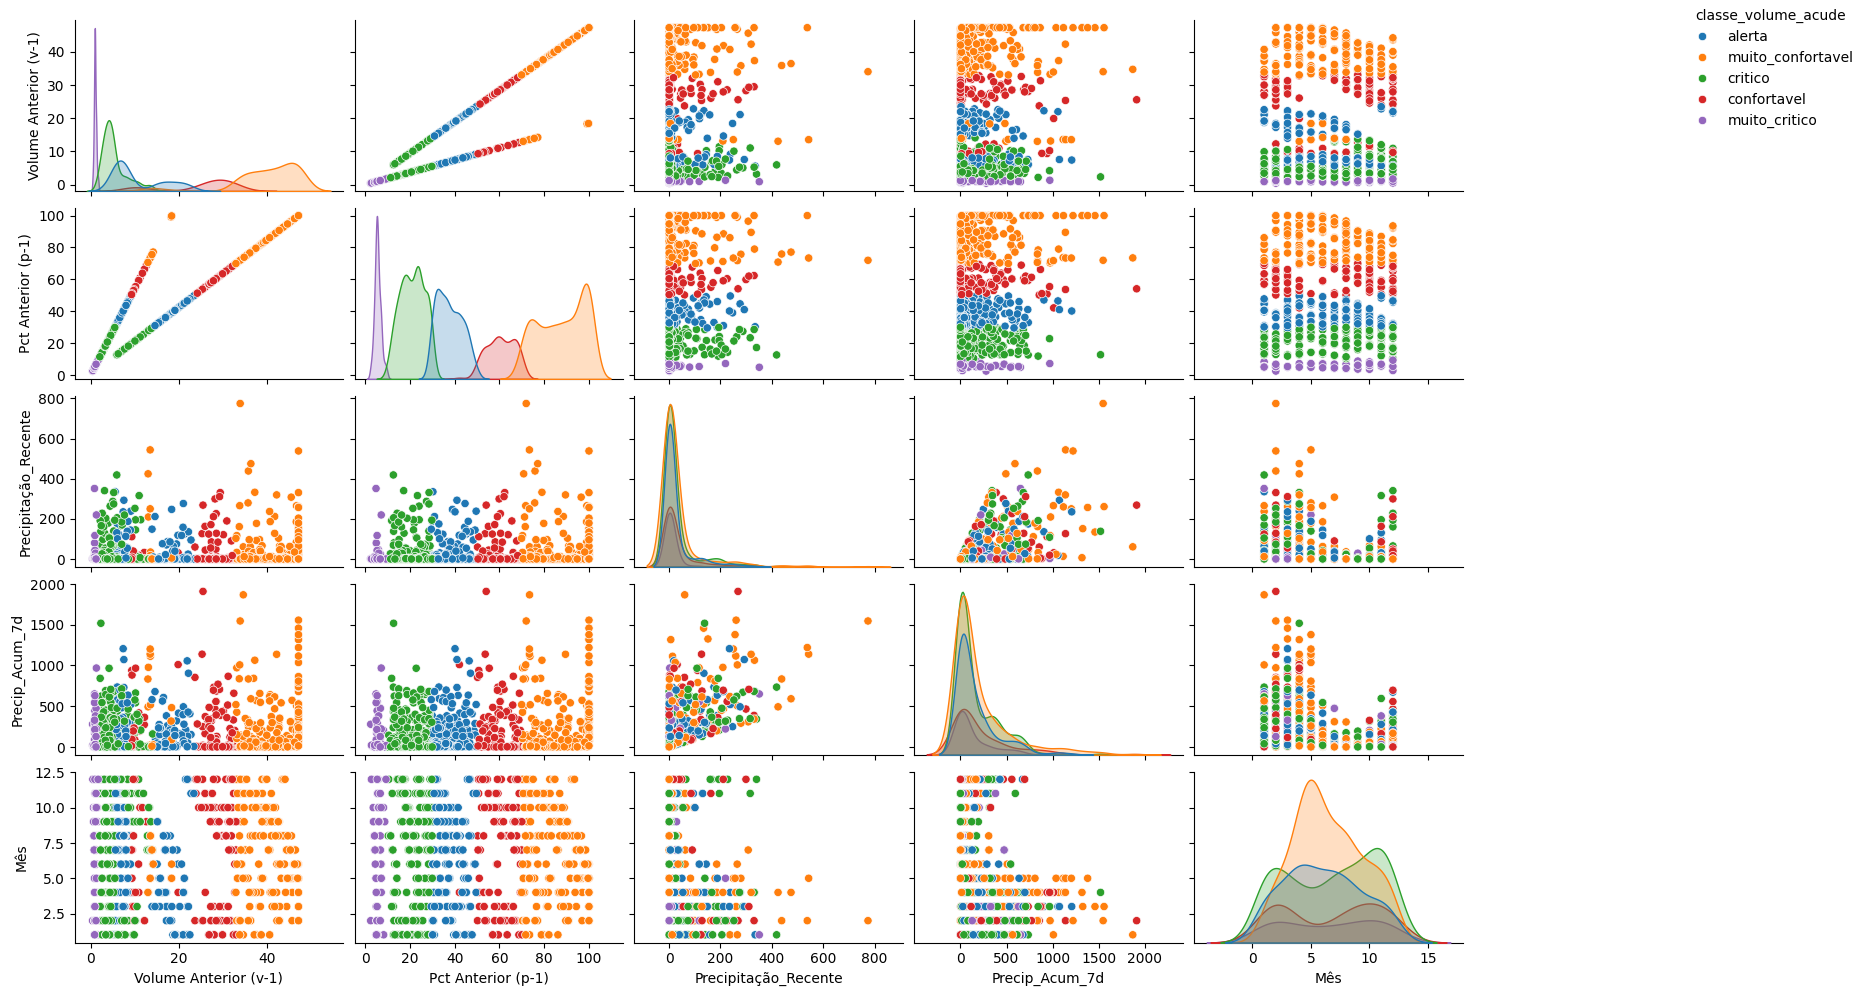

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# n=1000 para n travar o gráfico, mas pode ser ajustado conforme a capacidade do computador
amostra_plot = df_reduzido.drop(columns=["Data"]).sample(n=1000)

g = sns.pairplot(amostra_plot, hue="classe_volume_acude", height=2, aspect=1.5)
g._legend.set_bbox_to_anchor((1, 1))
g._legend.set_loc("upper left")
plt.show()

- Teste de Classificação Supervisionada

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("--- CLASSIFICAÇÃO (GaussianNB) ---")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.2%}")
print("\nRelatório de Classificação:\n", classification_report(y_test, y_pred, zero_division=0))

--- CLASSIFICAÇÃO (GaussianNB) ---
Acurácia: 89.29%

Relatório de Classificação:
                    precision    recall  f1-score   support

           alerta       0.85      0.79      0.82       712
      confortavel       0.81      0.81      0.81       435
          critico       0.87      0.93      0.90       864
muito_confortavel       0.96      0.95      0.96      1074
    muito_critico       0.97      0.98      0.97       230

         accuracy                           0.89      3315
        macro avg       0.89      0.89      0.89      3315
     weighted avg       0.89      0.89      0.89      3315



- Teste de Regressão Supervisionada

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
# Garantindo que temos as colunas numéricas e o alvo a partir de df_final (sem NaNs)
df_reg = df_final.dropna(subset=['Volume Atual', 'Volume Anterior (v-1)', 'Precipitação_Recente']).copy()
df_reg['Mês'] = df_reg['Data'].dt.month

# Substituímos 'Data' por 'Mês' (numérico)
X_reg = df_reg[['Mês', 'Precipitação_Recente', 'Volume Anterior (v-1)']]
y_reg = df_reg['Volume Atual']

X_tr, X_te, y_tr, y_te = train_test_split(X_reg, y_reg, test_size=0.25, random_state=42)

reg_model = LinearRegression()
reg_model.fit(X_tr, y_tr)

y_reg_pred = reg_model.predict(X_te)
print("--- REGRESSÃO LINEAR ---")
print(f"R² Score: {r2_score(y_te, y_reg_pred):.4f}")
print(f"Erro Quadrático Médio (MSE): {mean_squared_error(y_te, y_reg_pred):.4f}\n")

--- REGRESSÃO LINEAR ---
R² Score: 0.9998
Erro Quadrático Médio (MSE): 0.0445



- Teste Não Supervisionado (PCA e K-Means)

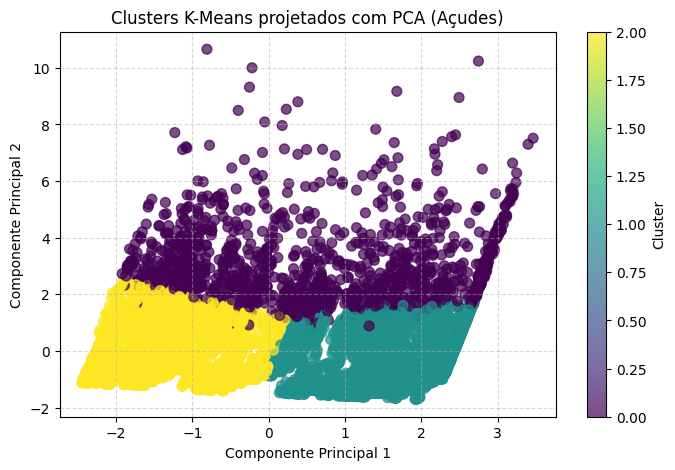

In [35]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Padronizar X antes de aplicar PCA e K-Means
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA para 2D
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_scaled)

# K-Means com 3 grupos
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
clusters = kmeans.fit_predict(X_scaled)

# Visualização
plt.figure(figsize=(8, 5))
plt.scatter(X_2D[:, 0], X_2D[:, 1], c=clusters, cmap='viridis', s=50, alpha=0.7)
plt.title("Clusters K-Means projetados com PCA (Açudes)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.colorbar(label="Cluster")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()